In [44]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

# Problem 1

The chance of 2 dices rolling 2 is 1 in 36 since the dices have to be 1+1. \
But, for them to roll 7, the dices can be 1+6, 2+5, 3+4, 4+3, 5+2, 6+1 which provides 6 in 36 possible combinations. \
The ratio of probabilities of rolling 2 vs rolling 7 is 1/6.

# Problem 2
$$P(i)=\frac{1}{6} $$
for i in [1,2,3,4,5,6]
$$P(x)=\sum_{i=1}^{i=6} P(i)P(x-i)$$
for x=2, $P(x)=P(1)P(1)=\frac{1}{36}$ \
for x=7, $P(x)=\sum_{i=1}^{i=6} P(i)P(7-i)=6*\frac{1}{36}=\frac{1}{6}$

<BarContainer object of 11 artists>

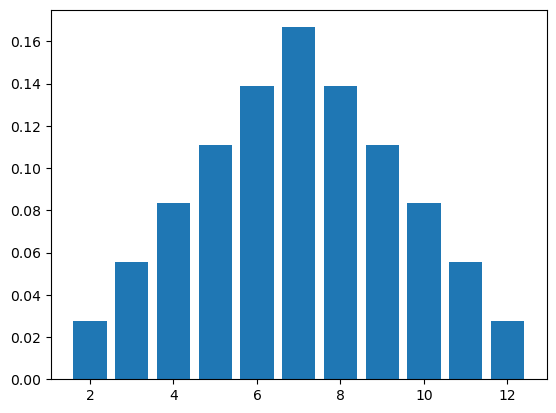

In [45]:
dice=np.ones(6)/6
dice2=np.convolve(dice, dice,mode='full')
x2=np.arange(2,13)
plt.bar(x2,dice2)

# Problem 3
Mean of 1 dice: $$\mu_1 = \frac{\sum x}{6} = \frac{1+2+3+4+5+6}{6} = \frac{21}{6} = 3.5$$
Mean of 2 dices: $$\mu_2 = \sum P(x)*x = \frac{1*2+2*3+3*4+4*5+5*6+6*7+5*8+4*9+3*10+2*11+1*12}{36} = \frac{252}{36} = 7 = 2*\mu_1$$
Variance of 1 dice: $$\sigma^2_1 = \frac{\sum (x-\mu_1)^2}{6} = \frac{\sum x^2-2\mu_1 x+\mu^2_1}{6} = \frac{\sum x^2}{6}-2\mu^2_1+\mu^2_1 = \frac{\sum x^2}{6}-\mu^2_1$$
$$= \frac{1+4+9+16+25+36}{6}-3.5^2 = \frac{91}{6}-\frac{49}{4} = \frac{182-147}{12} = \frac{35}{12} \approx 2.917$$
Variance of 2 dices: $$\sigma^2_2 = \sum(P(x)*x^2) -\mu^2_2 = \frac{1*2^2+2*3^2+3*4^2+4*5^2+5*6^2+6*7^2+5*8^2+4*9^2+3*10^2+2*11^2+1*12^2}{36}-7^2$$
$$= \frac{1974}{36}-49 = \frac{329-294}{6} = \frac{35}{6} = 2\sigma^2_1 \approx 5.833$$

In [65]:
x1=np.arange(1,7)
mu1=np.sum(dice*x1)
mu2=np.sum(dice2*x2)
var1=np.sum(dice*x1**2)-mu1**2
var2=np.sum(dice2*x2**2)-mu2**2
print(f"Mean of 1 dice: {mu1:.3f}")
print(f"Mean of 2 dices: {mu2:.3f}")
print(f"Variance of 1 dice: {var1:.3f}")
print(f"Variance of 1 dice: {var2:.3f}")

Mean of 1 dice: 3.500
Mean of 2 dices: 7.000
Variance of 1 dice: 2.917
Variance of 1 dice: 5.833


# Problem 4

In [47]:
dice=np.ones(6)/6
def Ndicecv(n):
    result=dice
    for i in range(n-1):
        result=np.convolve(result, dice,mode='full')
    return result


In [48]:
dice10=Ndicecv(10)

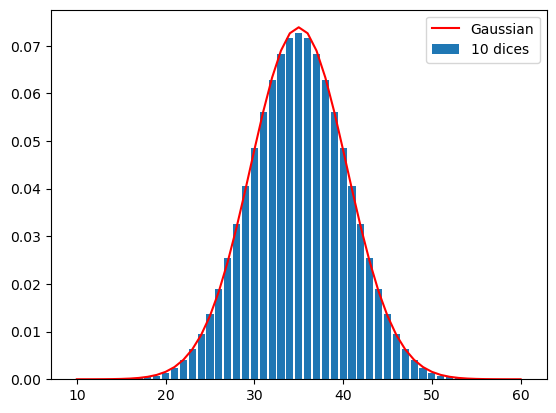

In [49]:
x10=np.arange(10,61)
plt.bar(x10,Ndicecv(10),label='10 dices')

gauss=norm.pdf(x10,10*3.5,(10*35/12)**(1/2))
plt.plot(x10,gauss,c='r',label='Gaussian')
plt.legend()

Although it fits Gaussian, it is not Gaussian since the values are discrete meaning that the values only exist if they are integers in between 10 and 60. So, probability of x at something like 23.5 or 80 is 0.

# Problem 5
n is an element of Gaussian, N is the number of Gaussians, $P_N$ is the probability from convolution N times. \
The sum of Gaussian results in wider Gaussian as we see in convolution, which would have the mean $\mu_N = \sum P_N(x)*x =  N*\mu$ \
And, the standard deviation $\sigma_N = \sqrt{\sum P_N(x)*x^2 - \mu_N^2} = \sqrt{N*\sigma^2} = \sqrt{N}*\sigma$. \
The average of Gaussian results in sharper Gaussian, basically sum of Gaussian divide by N. The mean would be
$\mu_A = \frac{\mu_N}{N} = \mu$ \
And, standard deviation $\sigma_A = \frac{\sigma_N}{N} = \frac{\sigma}{\sqrt{N}}$ \
The more you average the Gaussian, the more precise it becomes.